In [1]:
import pandas as pd
import matplotlib.pyplot as plt
# tables
df_fact = pd.read_csv("data/nyc_flights_fixed.csv")
df_weather = pd.read_csv("data/nyc_weather.csv")
# dims
dim_airports = pd.read_csv("data/nyc_airports.csv")
dim_airlines = pd.read_csv("data/nyc_airlines.csv")
dim_planes = pd.read_csv("data/nyc_planes.csv")
# chekc duplicates in faa
assert dim_airports.faa.duplicated().sum() == 0
assert dim_planes.tailnum.duplicated().sum() == 0
assert dim_airlines.carrier.duplicated().sum() == 0

In [2]:
table = (
    df_fact
    .merge(dim_airports, left_on="origin", right_on="faa", how="left", suffixes=("", "_airport"))
    .merge(dim_airlines, left_on="carrier", right_on="carrier", how="left", suffixes=("", "_airline"))
    .merge(dim_planes, left_on="tailnum", right_on="tailnum", how="left", suffixes=("", "_plane"))
)

# Select Airport

In [3]:
# OPTIONS: 'Newark Liberty Intl', 'La Guardia', 'John F Kennedy Intl', 'ALL'
selected_airport = 'ALL'

if selected_airport != 'ALL':
    table = table[table["airport"] == selected_airport]
    table = table.copy()

In [5]:
# create date
table["date"] = pd.to_datetime(table[["year", "month", "day"]])
# Calculate the rounded average of distinct destinations for each day.
avg_distinct_destinations = (
    table.groupby("date").agg({"dest":'nunique'})
    .dest.mean()
)
# Calculate the average number of destinations per day of the week.
# week day
week_day = lambda x: x.weekday()
table['weekday'] = table['date'].apply(week_day)
# map weekday numbers to names
weekday_map = {0:'Monday', 1:'Tuesday', 2:'Wednesday', 3:'Thursday', 4:'Friday', 5:'Saturday', 6:'Sunday'}
table['weekday'] = table['weekday'].map(weekday_map)
# avg
avg_dest_per_weekday = (
    table.groupby(['weekday', 'date'])['dest']
    .nunique()
    .groupby('weekday')
    .mean()
)
# Identify the month with the highest number of flights.
## map month numbers to names
month_map = {1:'January', 2:'February', 3:'March', 4:'April', 5:'May', 6:'June', 7:'July', 8:'August', 9:'September', 10:'October', 11:'November', 12:'December'}
table['month'] = table['month'].map(month_map)
# Identify the month with the highest number of flights.
monthly_flights = df_fact.groupby("month").size()
month_number = int(monthly_flights.idxmax())

# Identify the month with the highest accumulated departure delay.
monthly_departure_delay = df_fact.groupby("month")["dep_delay"].sum()
month_number = int(monthly_departure_delay.idxmax())
# Analyze the correlation between departure delay and weather conditions by cross-referencing the departure delay data with the weather dataset.
merged_df = pd.merge(df_fact, df_weather, on=["year", "month", "day", "hour"], how="left")
correlation = merged_df["dep_delay"].corr(merged_df["temp"])
# Create a ranking of airlines based on the number of flights they operate.
airline_ranking = table.groupby("carrier").size().sort_values(ascending=False)
# Create a ranking of airlines based on the daily availability of seats.
airline_seat_ranking = (
    table.groupby(["date", "carrier"])["seats"]
    .sum()
    .groupby("carrier")
    .mean()
    .sort_values(ascending=False)
)
# Determine the most common plane manufacturer.
most_common_manufacturer = table["manufacturer"].value_counts().idxmax()
# Identify the most common plane model.
most_common_model = table["model"].value_counts().idxmax()

# Results

In [7]:
print("=" * 60)
print("OVERALL PANE:")
print("=" * 60)
num_distinct_dest = table["dest"].nunique()
print(f"1. Number of distinct destinations: {num_distinct_dest}")

# 2. Rounded average of distinct destinations for each day
print(f"2. Rounded average of distinct destinations per day: {round(avg_distinct_destinations)} (Exact: {avg_distinct_destinations:.2f})")

# 3. Average number of destinations per day of the week
print("3. Average number of destinations per day of the week:")
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
ordered_weekdays = avg_dest_per_weekday.reindex([d for d in days_order if d in avg_dest_per_weekday.index])
for day, avg_val in ordered_weekdays.items():
    print(f"   - {day:<9}: {avg_val:.2f}")

# 4. Month with the highest number of flights
best_flights_month_id = int(monthly_flights.idxmax())
best_flights_month_name = month_map.get(best_flights_month_id, str(best_flights_month_id))
print(f"4. Month with highest number of flights: {best_flights_month_name} ({monthly_flights.max():,} flights)")


print("\n" + "=" * 60)
print("DEALING WITH DELAYS:")
print("=" * 60)

# 5. Month with the highest accumulated departure delay
best_delay_month_id = int(monthly_departure_delay.idxmax())
best_delay_month_name = month_map.get(best_delay_month_id, str(best_delay_month_id))
print(f"5. Month with highest accumulated departure delay: {best_delay_month_name} ({monthly_departure_delay.max():,.0f} mins)")

# 6. Correlation between departure delay and weather (temperature)
print(f"6. Correlation between departure delay and temperature: {correlation:.4f}")


print("\n" + "=" * 60)
print("AIRLINES:")
print("=" * 60)

# 7. Ranking of airlines based on number of flights
print("7. Ranking of airlines by number of flights:")
display(airline_ranking)


# 8. Ranking of airlines based on daily availability of seats
print("\n8. Ranking of airlines by daily availability of seats:")
display(airline_seat_ranking)


print("\n" + "=" * 60)
print("AIRPLANES:")
print("=" * 60)

# 9. Most common plane manufacturer
mfg_count = table["manufacturer"].value_counts().max()
print(f"9. Most common plane manufacturer: {most_common_manufacturer} ({mfg_count:,} flights)")

# 10. Most common plane model
model_count = table["model"].value_counts().max()
print(f"10. Most common plane model: {most_common_model} ({model_count:,} flights)")
print("=" * 60)

OVERALL PANE:
1. Number of distinct destinations: 100
2. Rounded average of distinct destinations per day: 81 (Exact: 81.08)
3. Average number of destinations per day of the week:
   - Monday   : 81.79
   - Tuesday  : 80.40
   - Wednesday: 80.48
   - Thursday : 82.56
   - Friday   : 81.92
   - Saturday : 77.40
   - Sunday   : 83.00
4. Month with highest number of flights: August (24,290 flights)

DEALING WITH DELAYS:
5. Month with highest accumulated departure delay: July (535,995 mins)
6. Correlation between departure delay and temperature: 0.0582

AIRLINES:
7. Ranking of airlines by number of flights:


carrier
UA    55802
EV    54173
B6    50194
DL    46669
US    19837
9E    17416
WN    12237
AA    10090
VX     5162
FL     3073
MQ     1000
AS      714
F9      635
YV      601
HA      342
OO       32
dtype: int64


8. Ranking of airlines by daily availability of seats:


carrier
UA    27014.476712
DL    21558.830137
B6    17856.287671
US     9446.010959
EV     8822.931507
AA     5432.731507
WN     4725.863014
9E     3783.780822
VX     2517.961644
FL      903.684932
HA      377.000000
AS      358.268493
F9      319.591036
YV      164.867089
OO       79.531250
MQ       44.183051
Name: seats, dtype: float64


AIRPLANES:
9. Most common plane manufacturer: BOEING (80,345 flights)
10. Most common plane model: A320-232 (42,423 flights)



DEALING WITH DELAYS:


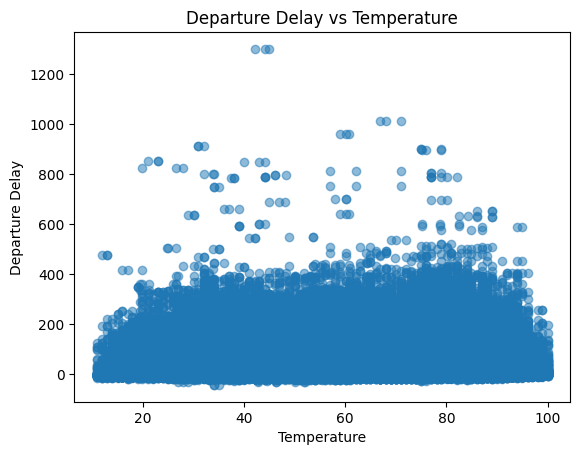

In [9]:
print("\n" + "=" * 60)
print("DEALING WITH DELAYS:")
print("=" * 60)
# scatter plot of departure delay vs temperature
plt.scatter(merged_df["temp"], merged_df["dep_delay"], alpha=0.5)
plt.xlabel("Temperature")
plt.ylabel("Departure Delay")
plt.title("Departure Delay vs Temperature")
plt.savefig("departure_delay_vs_temperature.png")
plt.show()